In [1]:
# numpy is for linear algebra -> working with matrices
import numpy as np
# pandas is for reading data
import pandas as pd 
# pyplot is for showing images
from matplotlib import pyplot as plt

In [2]:
# importing data
data = pd.read_csv('/kaggle/input/competitions/digit-recognizer/train.csv')

In [3]:
data.shape

(42000, 785)

In [4]:
# we will be working with numpy arrays instead of pandas dataframe
data = np.array(data)
# dimensions of dataset/matrix
m, n = data.shape
# we will be shuffling the datasest and spliting it into dev and trainng dataset
np.random.shuffle(data)

# dev data -> source of truth data on which we dont perform and training so that we can validate it later
# we are transposing the dataset so that each column is an example rather than each row
data_dev = data[0:1000].T
# taking the first row -> all labels
Y_dev = data_dev[0]
# taking everything except the first row of labels 
# i.e, matrix of all 1000 images and their 784 pixel values where rows will be pixel values and columns indicate individual image
X_dev = data_dev[1:n]
# normailising dev data
X_dev = X_dev/255

# training dataset
data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]
# normalising training data
X_train = X_train/255

In [5]:
m, n

(42000, 785)

In [6]:
# our starting function which will have weights and biases
def init_params() :
    # initially we will be assuming some random weights
    # we have 784 input neurons and 10 neurons in 1st hidden layer
    # we map each input neuron with neurons in hidden layer, hence -> 10 rows with 784 columns
    W1 = np.random.rand(10,784) - 0.5
    # bias will also be random
    # each neuron in hidden layer will have its own bias
    # hence, 10 biasses for 1st hidden layer of 10 neurons
    b1 = np.random.rand(10, 1) - 0.5
    # in 1st hidden layer we have 10 neurons and in output layer too we have 10 neurons 
    # hence mapping of 10x10
    W2 = np.random.rand(10, 10) - 0.5
    b2 = np.random.rand(10, 1) - 0.5
    return W1, b1, W2, b2

# defining Rectified Linear Unit -> our activation function for first layer
def ReLU(Z) :
    # returns 0 if element is less than or equal to zero, else returns that element itself
    return np.maximum(0,Z)

# defining Softmax function -> our activation function for second layer
def softMax(Z) : 
    # each of the 10 nodes in our output/2nd layer should correspond to probabilities of each digits(0-9)
    # print("softmax : ",Z, np.exp(Z)/np.sum(np.exp(Z)))
    exp_Z = np.exp(Z)
    return exp_Z / np.sum(exp_Z, axis=0, keepdims=True)
    

# derivative of ReLU (first layer's activation function)
def deriv_ReLU(Z) :
    return Z > 0


# function with forward propagation
def forward_prop(W1, b1, W2, b2, X) :
    # calculation of unactivated first layer 
    Z1 = W1.dot(X) + b1
    # calculation of activated first layer
    A1 = ReLU(Z1)
    # calculation of unactivated second layer
    Z2 = W2.dot(A1) + b2
    # calculation of activated second layer
    A2 = softMax(Z2)
    return Z1, A1, Z2, A2

# one_hot function ???
def one_hot(Y) : 
    one_hot_Y = np.zeros((Y.size, Y.max() + 1))
    one_hot_Y[np.arange(Y.size), Y] = 1
    one_hot_Y = one_hot_Y.T
    return one_hot_Y

# function with backward propagation
def backward_prop(Z1, A1, Z2, A2, W2, X, Y) :
    m= Y.size
    one_hot_Y = one_hot(Y)
    # deviation in 2nd or output layer is our prediction - actual answer in one hot encoded format
    dZ2 = A2 - one_hot_Y
    # deviation in weights of 2nd layer
    dW2 = 1/m * dZ2.dot(A1.T)
    # deviation in bias of 2nd layer
    db2 = 1/m * np.sum(dZ2, axis=1, keepdims=True)

    dZ1 = (W2.T).dot(dZ2) * deriv_ReLU(Z1)
    dW1 = 1/m * dZ1.dot(X.T)
    db1 = 1/m * np.sum(dZ1, axis=1, keepdims=True)

    return dW1, db1, dW2, db2

# for getting improved results
def update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha) :
    W1 = W1 - alpha * dW1
    b1 = b1 - alpha * db1
    W2 = W2 - alpha * dW2
    b2 = b2 - alpha * db2
    return W1, b1, W2, b2

    

In [7]:
def get_predictions(A2) : 
    return np.argmax(A2, 0)

def get_accuracy(predictions, Y) : 
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size

def gradient_descent(X, Y, iterations, alpha) : 
    # using our init_params() function to get initial weights and biases
    # alpha is learning rate
    W1, b1, W2, b2 = init_params()
    for i in range(iterations) : 
        # using forward_prop() funtion to get activated and unactivated 1st, 2nd layers value
        Z1, A1, Z2, A2 = forward_prop(W1, b1, W2, b2, X)
        # using backward_prop() function to get deviation in weights and biases
        dW1, db1, dW2, db2 = backward_prop(Z1, A1, Z2, A2, W2, X, Y)
        # now, to improve results of weights and biases using the deviations found
        W1, b1, W2, b2 = update_params(W1, b1, W2, b2, dW1, db1, dW2, db2, alpha)
        # we will print results every 50th iteration
        if i % 10 == 0:
            print("Iteration : ", i)
            print("Accuracy : ", get_accuracy(get_predictions(A2), Y))

    return W1, b1, W2, b2

In [8]:
W1, b1, W2, b2 = gradient_descent(X_train, Y_train, 500, 0.1)

Iteration :  0
[3 8 7 ... 7 7 7] [1 6 6 ... 2 9 7]
Accuracy :  0.11307317073170732
Iteration :  10
[3 4 3 ... 4 3 9] [1 6 6 ... 2 9 7]
Accuracy :  0.19797560975609757
Iteration :  20
[8 8 3 ... 1 3 9] [1 6 6 ... 2 9 7]
Accuracy :  0.2624878048780488
Iteration :  30
[8 1 3 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.32851219512195123
Iteration :  40
[1 2 2 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.43821951219512195
Iteration :  50
[1 6 2 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.5140243902439025
Iteration :  60
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.5618536585365854
Iteration :  70
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.595780487804878
Iteration :  80
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.6230975609756098
Iteration :  90
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.6464878048780488
Iteration :  100
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.6658048780487805
Iteration :  110
[1 6 6 ... 1 9 7] [1 6 6 ... 2 9 7]
Accuracy :  0.6823902439024391


In [9]:
def make_predictions(X, W1, b1, W2, b2) :
    _, _, _, A2 = forward_prop(W1, b1, W2, b2, X)
    predictions = get_predictions(A2)
    return predictions

def test_predictions(index, W1, b1, W2, b2) : 
    current_image = X_train[:, index, None]
    prediction = make_predictions(current_image, W1, b1, W2, b2)
    label = Y_train[index]
    print("Prediction : ", prediction)
    print("Label : ", label)

    current_image = current_image.reshape((28, 28)) * 255
    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()
    

Prediction :  [9]
Label :  9


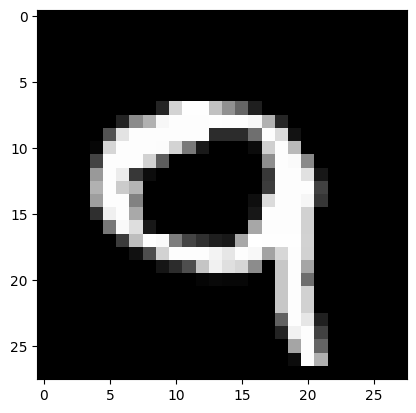

In [10]:
test_predictions(79, W1, b1, W2, b2)